# Лабораторная работа 3 - Метод наименьших квадратов. Линейная регрессия

Сгенерировать данные, используя заданное распределение и связанное уравнение.

Вариант 2:

- $N = 10\,000$ - количество точек
- $X$ - равномерное распределение от 1 до 50
- $E$ - нормальное распределение с центром 1 и отклонением 10
- $Y = -3 + 0.5X + E$

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)

N = 10_000
X = np.random.uniform(1, 50, N)
E = np.random.normal(1, 10, N)
Y = -3 + 0.5 * X + E

pd.DataFrame({"X": X, "E": E, "Y": Y}).head()

,X,E,Y
0,19.352466,-13.878617,-7.202384
1,47.585001,-10.251861,10.540639
2,36.867703,4.888189,20.322041
3,30.334266,-10.738733,1.428400
4,8.644913,12.126343,13.448800


Найти уравнение прямой линейной регрессии методом наименьших квадратов

$$\hat{y} = \beta_0 + \beta_1 x$$

Ищем такие $\beta_0, \beta_1$, при которых сумма квадратов остатков минимальна:

$$S(\beta_0, \beta_1) = \sum_{i=1}^{N} (y_i - \beta_0 - \beta_1 x_i)^2 \to \min$$

Приравниваем частные производные к нулю и получаем:

$$\beta_1 = \frac{N \sum x_i y_i - \sum x_i \sum y_i}{N \sum x_i^2 - (\sum x_i)^2}, \qquad \beta_0 = \bar{y} - \beta_1 \bar{x}$$

In [2]:
def mnk(x, y):
    n = len(x)
    b1 = (n * np.sum(x * y) - np.sum(x) * np.sum(y)) / (n * np.sum(x ** 2) - np.sum(x) ** 2)
    b0 = np.mean(y) - b1 * np.mean(x)
    return b0, b1

mnk(np.array([1, 2, 3, 4]), np.array([2, 3, 5, 6]))

(np.float64(0.5), np.float64(1.4))

Получить коэффициенты для линейной регрессии

In [3]:
b0, b1 = mnk(X, Y)

print("b0:", b0)
print("b1:", b1)
print("polyfit:", np.polyfit(X, Y, 1))

b0: -1.674211751986471
b1: 0.4919792279433698
polyfit: [ 0.49197923 -1.67421175]


Построить прямую согласно найденным коэффициентам и отобразить точки датасета

Построить прямую согласно выражению $Y$

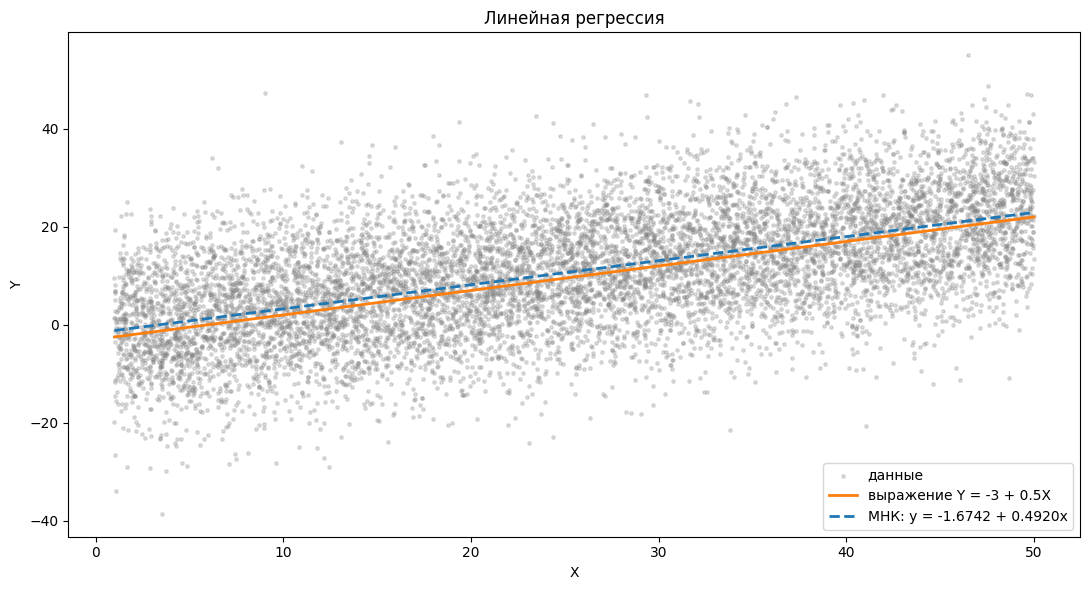

In [4]:
line_x = np.array([1, 50])

plt.figure(figsize=(11, 6))
plt.scatter(X, Y, s=6, alpha=0.25, color="gray", label="данные")
plt.plot(line_x, -3 + 0.5 * line_x, color="tab:orange", linewidth=2, label="выражение Y = -3 + 0.5X")
plt.plot(line_x, b0 + b1 * line_x, color="tab:blue", linestyle="--", linewidth=2, label=f"МНК: y = {b0:.4f} + {b1:.4f}x")
plt.title("Линейная регрессия")
plt.xlabel("X")
plt.ylabel("Y")
plt.legend()
plt.tight_layout()
plt.show()

Найти метрики оценки качества

$$MSE = \frac{1}{N} \sum (y_i - \hat{y}_i)^2$$

$$R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$$

$$MAPE = \frac{100\%}{N} \sum \left| \frac{y_i - \hat{y}_i}{y_i} \right|$$

In [5]:
def metrics(y, y_pred):
    mse = np.mean((y - y_pred) ** 2)
    r2 = 1 - np.sum((y - y_pred) ** 2) / np.sum((y - np.mean(y)) ** 2)
    mape = np.mean(np.abs((y - y_pred) / y)) * 100
    return mse, r2, mape

Y_pred = b0 + b1 * X
mse, r2, mape = metrics(Y, Y_pred)

print("MSE:", mse)
print("R^2:", r2)
print("MAPE:", mape, "%")

MSE: 99.9321258630935
R^2: 0.32481125740977757
MAPE: 250.97351348819384 %


Сравнить истинное и найденное решение

Среднее шума равно 1, а не 0, поэтому единица уходит в свободный член:

$$Y = -3 + 0.5X + E = (-3 + 1) + 0.5X + (E - 1) = -2 + 0.5X + (E - 1)$$

In [6]:
lines = {
    "выражение Y": (-3, 0.5),
    "с учётом среднего шума": (-2, 0.5),
    "МНК": (b0, b1),
}

rows = []
for name, (c0, c1) in lines.items():
    rows.append([name, c0, c1, *metrics(Y, c0 + c1 * X)])

pd.DataFrame(rows, columns=["прямая", "b0", "b1", "MSE", "R^2", "MAPE, %"]).set_index("прямая")

,b0,b1,MSE,R^2,"MAPE, %"
прямая,,,,,
выражение Y,-3.000000,0.500000,101.207277,0.316196,222.331140
с учётом среднего шума,-2.000000,0.500000,99.960169,0.324622,246.364462
МНК,-1.674212,0.491979,99.932126,0.324811,250.973513


Оценка качества по остаткам: остаток - это то, что модель не объяснила. Если прямая подходит, в остатках нет никакой закономерности

среднее остатков: -1.7848833522293715e-15
std остатков: 9.996605717096855
std шума E: 9.997244794380935


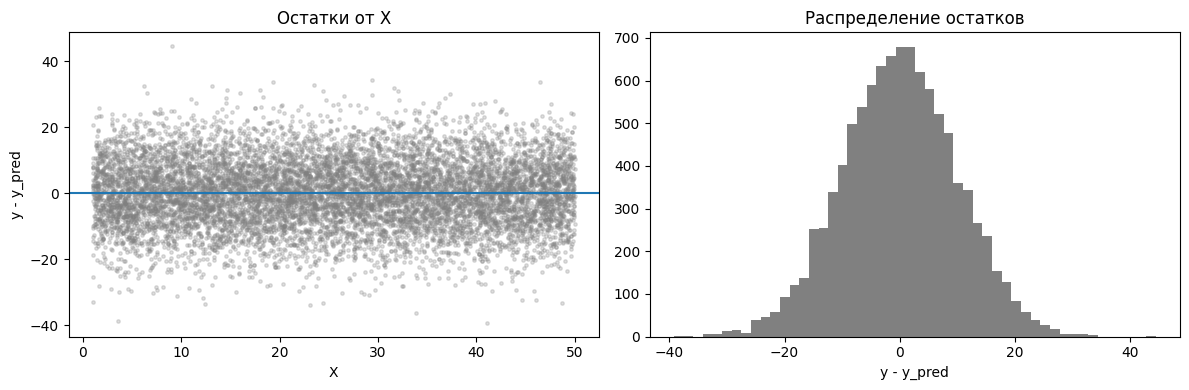

In [7]:
res = Y - Y_pred

print("среднее остатков:", res.mean())
print("std остатков:", res.std())
print("std шума E:", E.std())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(X, res, s=6, alpha=0.25, color="gray")
axes[0].axhline(0, color="tab:blue")
axes[0].set_title("Остатки от X")
axes[0].set_xlabel("X")
axes[0].set_ylabel("y - y_pred")

axes[1].hist(res, bins=50, color="gray")
axes[1].set_title("Распределение остатков")
axes[1].set_xlabel("y - y_pred")

plt.tight_layout()
plt.show()

Почему MAPE такой большой: в формуле мы делим на $y_i$, а часть значений $Y$ близка к нулю

доля точек с |Y| < 1: 0.0427
максимальная ошибка, %: 189064.7471553492
Y в этой точке: -0.0033518345318883647
медиана ошибки, %: 56.59736314732386
MAPE без точек с |Y| < 1: 101.61732862225539
MAPE без точек с |Y| < 5: 60.3608733719707


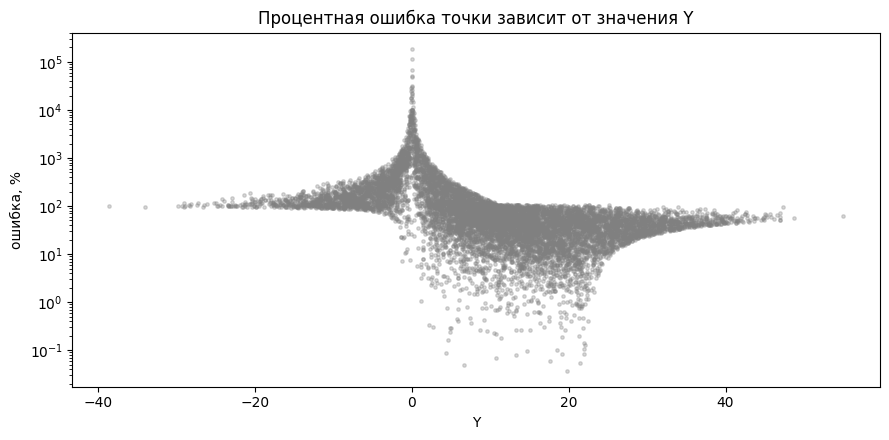

In [8]:
ape = np.abs((Y - Y_pred) / Y) * 100

print("доля точек с |Y| < 1:", np.mean(np.abs(Y) < 1))
print("максимальная ошибка, %:", ape.max())
print("Y в этой точке:", Y[ape.argmax()])
print("медиана ошибки, %:", np.median(ape))
print("MAPE без точек с |Y| < 1:", ape[np.abs(Y) >= 1].mean())
print("MAPE без точек с |Y| < 5:", ape[np.abs(Y) >= 5].mean())

plt.figure(figsize=(9, 4.5))
plt.scatter(Y, ape, s=6, alpha=0.3, color="gray")
plt.yscale("log")
plt.title("Процентная ошибка точки зависит от значения Y")
plt.xlabel("Y")
plt.ylabel("ошибка, %")
plt.tight_layout()
plt.show()

Вопрос 5. Нелинейная зависимость: прямая на параболе и на экспоненте, потом те же данные после преобразования

парабола, прямая по x: 0.000741995881918478
парабола, прямая по x^2: 0.9619330546761606
парабола, найдено: 2.3275224172720286 0.4914457457195767
экспонента, прямая по u: 0.6675648293931877
экспонента, прямая для log(v): 0.9397211108042501
экспонента, найдено: 2.0497117538290017 0.4984287312946031


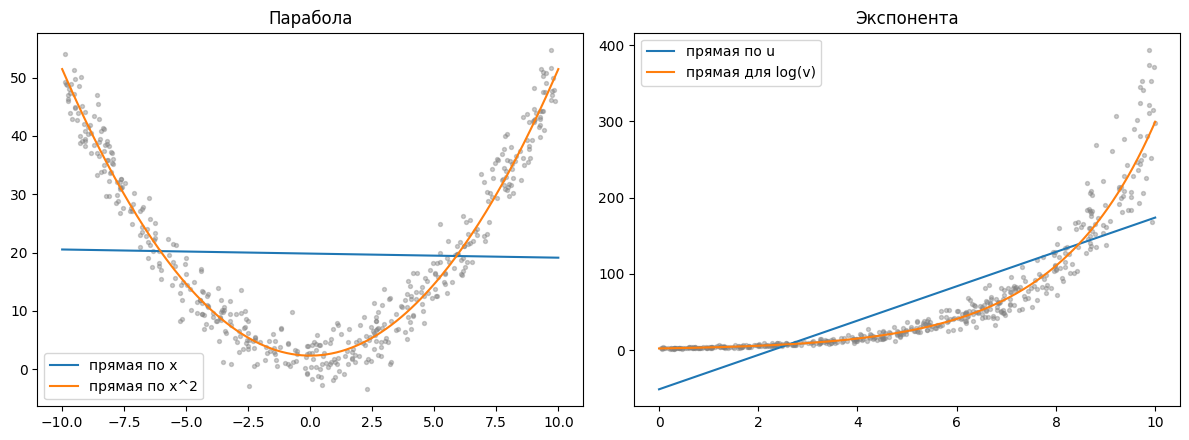

In [9]:
np.random.seed(42)

x = np.random.uniform(-10, 10, 500)
y = 2 + 0.5 * x ** 2 + np.random.normal(0, 3, 500)

p0, p1 = mnk(x, y)
q0, q1 = mnk(x ** 2, y)

u = np.random.uniform(0, 10, 500)
v = 2 * np.exp(0.5 * u) * np.exp(np.random.normal(0, 0.2, 500))

s0, s1 = mnk(u, v)
t0, t1 = mnk(u, np.log(v))

print("парабола, прямая по x:", metrics(y, p0 + p1 * x)[1])
print("парабола, прямая по x^2:", metrics(y, q0 + q1 * x ** 2)[1])
print("парабола, найдено:", q0, q1)
print("экспонента, прямая по u:", metrics(v, s0 + s1 * u)[1])
print("экспонента, прямая для log(v):", metrics(v, np.exp(t0 + t1 * u))[1])
print("экспонента, найдено:", np.exp(t0), t1)

gx = np.linspace(-10, 10, 200)
gu = np.linspace(0, 10, 200)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].scatter(x, y, s=8, alpha=0.4, color="gray")
axes[0].plot(gx, p0 + p1 * gx, color="tab:blue", label="прямая по x")
axes[0].plot(gx, q0 + q1 * gx ** 2, color="tab:orange", label="прямая по x^2")
axes[0].set_title("Парабола")
axes[0].legend()

axes[1].scatter(u, v, s=8, alpha=0.4, color="gray")
axes[1].plot(gu, s0 + s1 * gu, color="tab:blue", label="прямая по u")
axes[1].plot(gu, np.exp(t0 + t1 * gu), color="tab:orange", label="прямая для log(v)")
axes[1].set_title("Экспонента")
axes[1].legend()

plt.tight_layout()
plt.show()

Вопрос 6. Размер выборки: для каждого $N$ 1000 раз генерируем новые данные и смотрим, как разбегаются коэффициенты

In [10]:
def sample(n):
    x = np.random.uniform(1, 50, n)
    y = -3 + 0.5 * x + np.random.normal(1, 10, n)
    return x, y

np.random.seed(42)

rows = []
for n in [10, 100, 1000, 10000]:
    runs = []
    for _ in range(1000):
        x, y = sample(n)
        c0, c1 = mnk(x, y)
        mse_n, r2_n, _ = metrics(y, c0 + c1 * x)
        runs.append([c0, c1, mse_n, r2_n])
    runs = np.array(runs)
    rows.append([n, runs[:, 0].mean(), runs[:, 0].std(), runs[:, 1].mean(), runs[:, 1].std(), runs[:, 2].mean(), runs[:, 3].mean()])

pd.DataFrame(rows, columns=["N", "b0 среднее", "b0 std", "b1 среднее", "b1 std", "MSE", "R^2"]).set_index("N")

,b0 среднее,b0 std,b1 среднее,b1 std,MSE,R^2
N,,,,,,
10,-2.190959,6.995124,0.511671,0.249887,81.958261,0.374912
100,-1.946698,2.134697,0.497412,0.072657,97.849640,0.334290
1000,-1.981196,0.653817,0.498968,0.022293,99.929006,0.332384
10000,-1.997963,0.211038,0.499976,0.007067,99.984166,0.333363


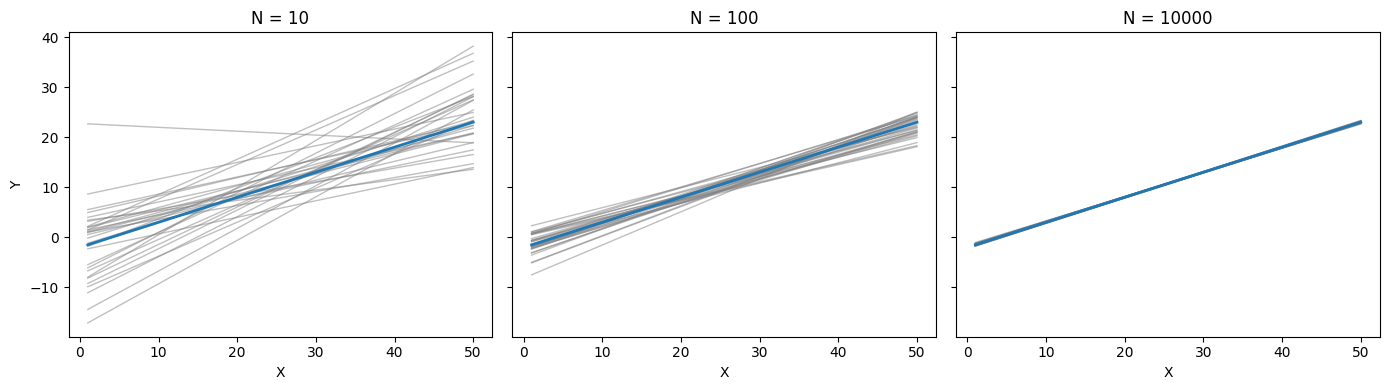

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)

for ax, n in zip(axes, [10, 100, 10000]):
    for _ in range(30):
        x, y = sample(n)
        c0, c1 = mnk(x, y)
        ax.plot(line_x, c0 + c1 * line_x, color="gray", alpha=0.5, linewidth=1)
    ax.plot(line_x, -2 + 0.5 * line_x, color="tab:blue", linewidth=2)
    ax.set_title(f"N = {n}")
    ax.set_xlabel("X")

axes[0].set_ylabel("Y")
plt.tight_layout()
plt.show()

Вопрос 7. Выбросы: добавим три точки с $Y = -100$ на правом краю и посмотрим, как сдвинется прямая

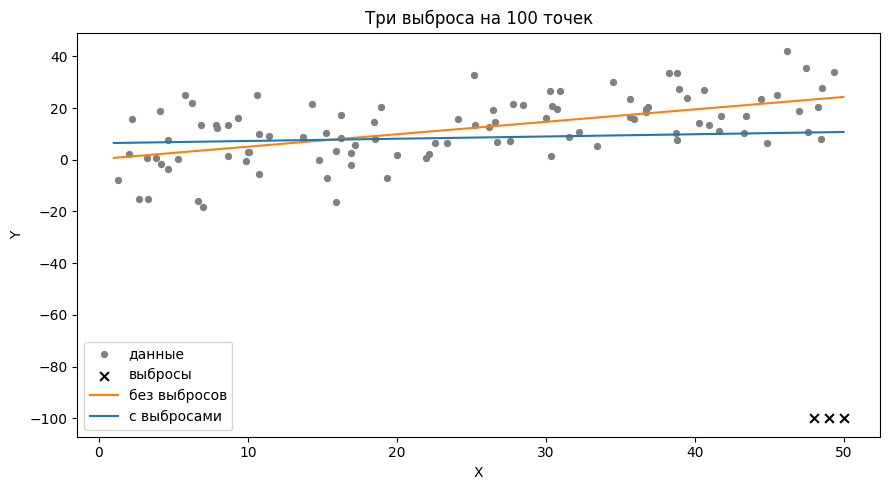

,b0,b1,MSE,R^2
выборка,,,,
100 точек,0.244514,0.480740,100.090573,0.326932
100 точек + 3 выброса,6.393665,0.086852,496.161043,0.003362
10 000 точек,-1.674212,0.491979,99.932126,0.324811
10 000 точек + 3 выброса,-1.600106,0.487585,104.392605,0.311567


In [12]:
out_x = np.array([48, 49, 50])
out_y = np.array([-100, -100, -100])

x100, y100 = X[:100], Y[:100]
x_bad = np.concatenate([x100, out_x])
y_bad = np.concatenate([y100, out_y])
X_bad = np.concatenate([X, out_x])
Y_bad = np.concatenate([Y, out_y])

rows = []
for name, xs, ys in [
    ("100 точек", x100, y100),
    ("100 точек + 3 выброса", x_bad, y_bad),
    ("10 000 точек", X, Y),
    ("10 000 точек + 3 выброса", X_bad, Y_bad),
]:
    c0, c1 = mnk(xs, ys)
    mse_n, r2_n, _ = metrics(ys, c0 + c1 * xs)
    rows.append([name, c0, c1, mse_n, r2_n])

clean = mnk(x100, y100)
dirty = mnk(x_bad, y_bad)

plt.figure(figsize=(9, 5))
plt.scatter(x100, y100, s=18, color="gray", label="данные")
plt.scatter(out_x, out_y, s=40, color="black", marker="x", label="выбросы")
plt.plot(line_x, clean[0] + clean[1] * line_x, color="tab:orange", label="без выбросов")
plt.plot(line_x, dirty[0] + dirty[1] * line_x, color="tab:blue", label="с выбросами")
plt.title("Три выброса на 100 точек")
plt.xlabel("X")
plt.ylabel("Y")
plt.legend()
plt.tight_layout()
plt.show()

pd.DataFrame(rows, columns=["выборка", "b0", "b1", "MSE", "R^2"]).set_index("выборка")